# ResNet-50 Evaluation and Visualization

In [3]:
import os
import sys

import pandas as pd
import tensorflow as tf

# Add the parent directory to the Python path to allow imports from sibling directories
sys.path.append(os.path.abspath(".."))

from data.dataset import prepare_cifar10_dataset, prepare_imagenette_dataset, prepare_oxford_pet_dataset
from models.model import MobileNet
from utils.trainer import MobileNetTransferTrainer
from models.loader import load_history_from_csv
from utils.visualize import plot_training_hist_dict, plot_confusion_matrix, plot_sample_predictions

# Check TensorFlow version and available devices
print("TensorFlow Version:", tf.__version__)
print("Devices available:", tf.config.list_physical_devices())

TensorFlow Version: 2.21.0
Devices available: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Evaluation on Imagenette dataset

In [4]:
DATASET_NAME = "imagenette"
BATCH_SIZE = 64

_, _, test_ds = prepare_imagenette_dataset(batch_size=BATCH_SIZE)

print(f"\nSuccessfully loaded {DATASET_NAME.upper()} data pipelines.")


Successfully loaded IMAGENETTE data pipelines.


In [5]:
# Path for best saved model
BEST_MODEL_PATH = f"../saved_models/mobilenet_{DATASET_NAME}_best_model.keras"

if os.path.exists(BEST_MODEL_PATH):
    model = tf.keras.models.load_model(BEST_MODEL_PATH)
    print("Best model loaded successfully.")
else:
    raise FileNotFoundError("No saved model or weights found. Please train the model first.")

Best model loaded successfully.


In [6]:
# Display network architecture summary
model.summary()

Model: "MobileNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_tensor_5CLONE             │ (None, 224, 224, 3)    │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,744,160 (25.73 MB)

 Trainable params: 2,236,682 (8.53 MB)

 Non-trainable params: 34,112 (133.25 KB)

 Optimizer params: 4,473,366 (17.06 MB)

Training history loaded successfully.


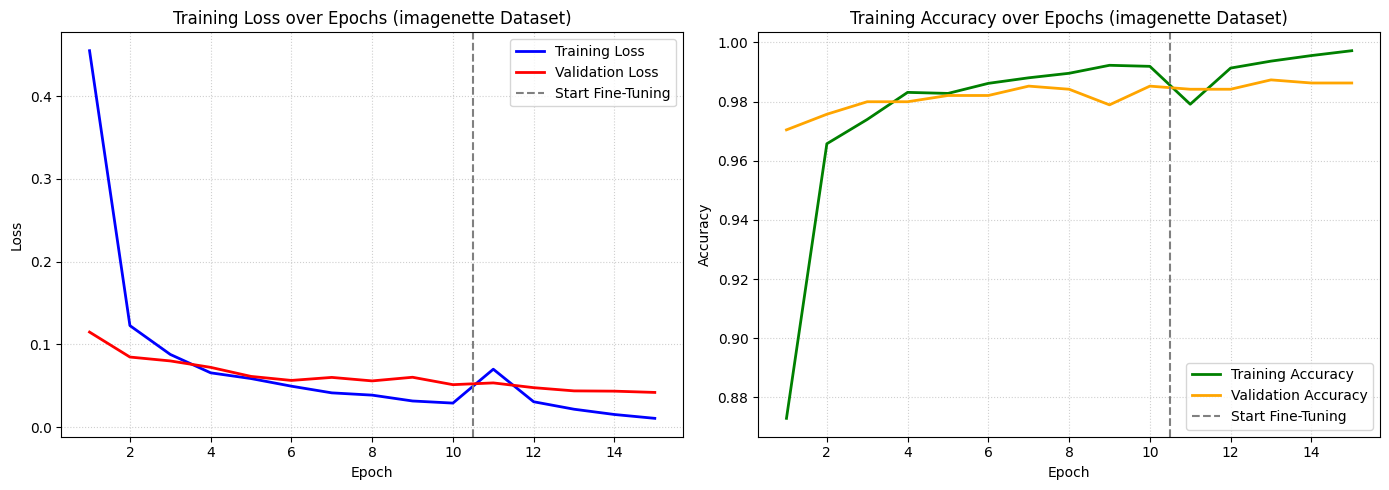

In [7]:
HISTORY_PATH = f"../saved_models/mobilenet_{DATASET_NAME}_history.csv"

if os.path.exists(HISTORY_PATH):
    # Load history from CSV file into a Pandas DataFrame
    history_dict = load_history_from_csv(HISTORY_PATH, warmup_epochs=10)
    print("Training history loaded successfully.")
else:
    raise FileNotFoundError(f"History file not found at: {HISTORY_PATH}")

# Plot training & validation loss and accuracy curves across epochs
plot_training_hist_dict(history_dict, dataset_name=DATASET_NAME)

In [8]:
trainer = MobileNetTransferTrainer(model=model)

# Evaluate model performance on unseen test data
results = trainer.evaluate(test_ds, dataset_name=DATASET_NAME)

print(f"Test Accuracy ({DATASET_NAME.upper()}): {results['accuracy'] * 100:.2f}%")
print(f"Test Loss ({DATASET_NAME.upper()}): {results['loss']:.4f}")

--- Evaluating MobileNet on (imagenette) Test Data ---
62/62 ━━━━━━━━━━━━━━━━━━━━ 18s 143ms/step - accuracy: 0.9783 - loss: 0.0763 - top_2_accuracy: 0.9926
Test Accuracy (IMAGENETTE): 97.83%
Test Loss (IMAGENETTE): 0.0763


62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 116ms/step


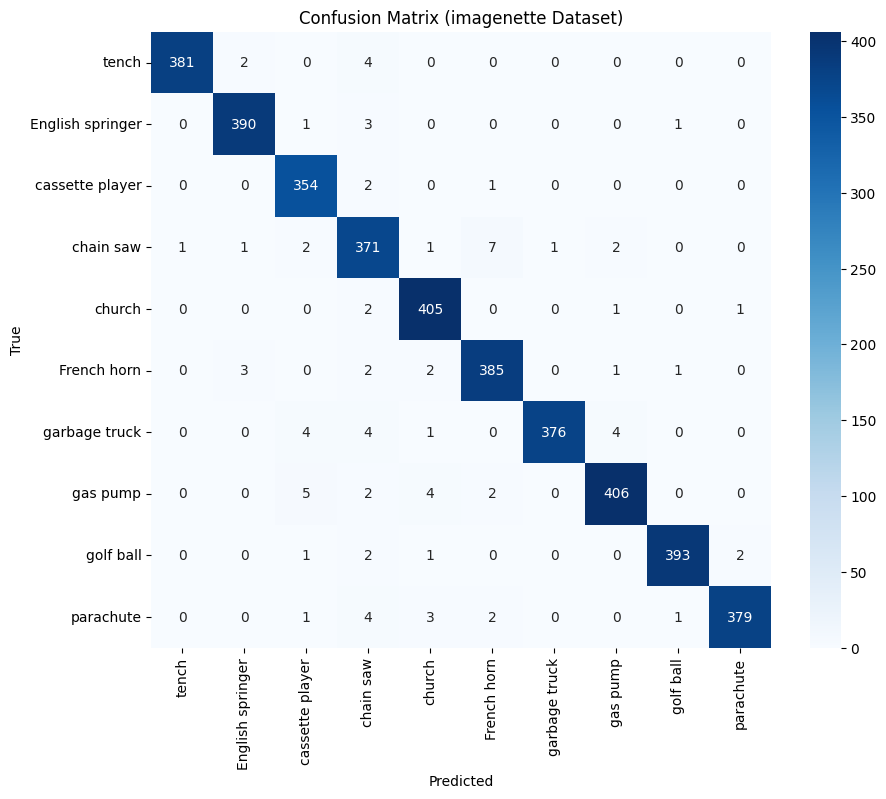

In [9]:
# Generate and display normalized confusion matrix heatmap
plot_confusion_matrix(
    model=model,
    dataset=test_ds,
    dataset_name=DATASET_NAME)

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


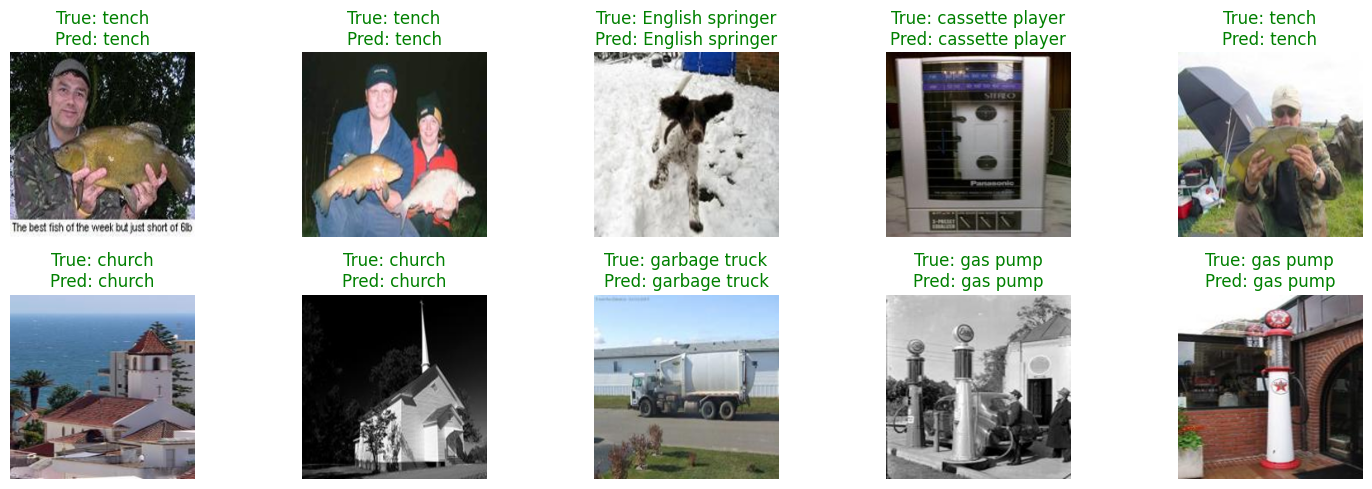

In [10]:
# Visualize random test set samples with green/red prediction status labels
plot_sample_predictions(
    model=model,
    dataset=test_ds,
    dataset_name=DATASET_NAME,
    num_samples=10
)

## Evaluation on CIFAR-10 dataset

In [5]:
DATASET_NAME = "cifar10"
BATCH_SIZE = 64

_, _, test_ds = prepare_cifar10_dataset(batch_size=BATCH_SIZE)

print(f"\nSuccessfully loaded {DATASET_NAME.upper()} data pipelines.")


Successfully loaded CIFAR10 data pipelines.


In [13]:
# Path for best saved model
BEST_MODEL_PATH = f"../saved_models/mobilenet_{DATASET_NAME}_best_model.keras"

if os.path.exists(BEST_MODEL_PATH):
    model = tf.keras.models.load_model(BEST_MODEL_PATH)
    print("Best model loaded successfully.")
else:
    raise FileNotFoundError("No saved model or weights found. Please train the model first.")

Best model loaded successfully.


In [14]:
# Display network architecture summary
model.summary()

Model: "MobileNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_tensor_5CLONE             │ (None, 224, 224, 3)    │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,296,416 (8.76 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 25,622 (100.09 KB)

Training history loaded successfully.


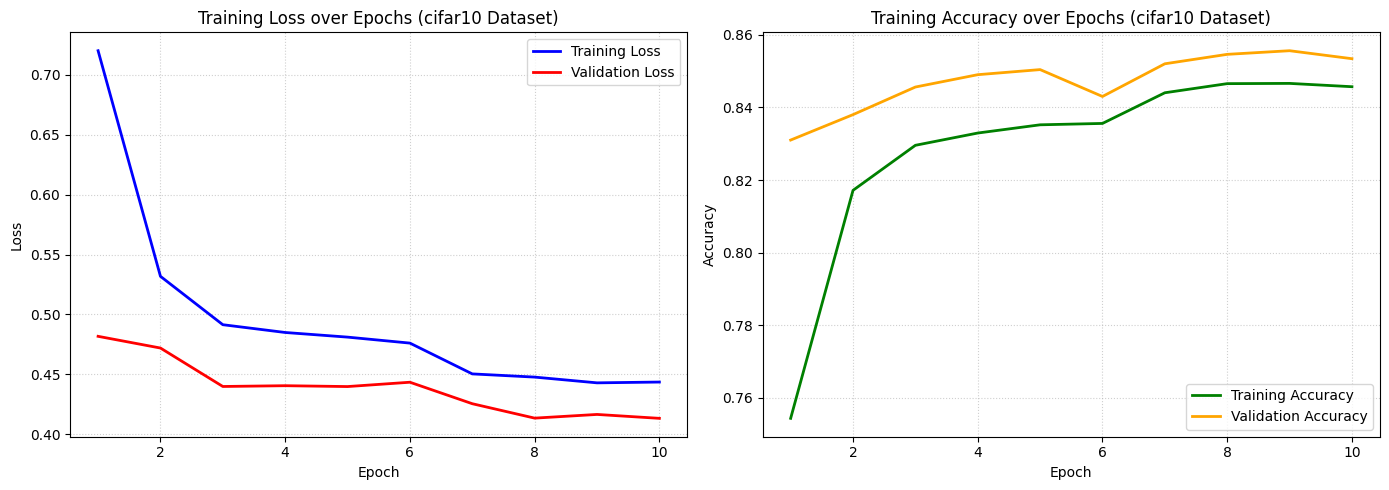

In [17]:
HISTORY_PATH = f"../saved_models/mobilenet_{DATASET_NAME}_history.csv"

if os.path.exists(HISTORY_PATH):
    # Load history from CSV file into a Pandas DataFrame
    history_dict = load_history_from_csv(HISTORY_PATH, warmup_epochs=10)
    print("Training history loaded successfully.")
else:
    raise FileNotFoundError(f"History file not found at: {HISTORY_PATH}")

# Plot training & validation loss and accuracy curves across epochs
plot_training_hist_dict(history_dict, dataset_name=DATASET_NAME)

In [18]:
trainer = MobileNetTransferTrainer(model=model)

# Evaluate model performance on unseen test data
results = trainer.evaluate(test_ds, dataset_name=DATASET_NAME)

print(f"Test Accuracy ({DATASET_NAME.upper()}): {results['accuracy'] * 100:.2f}%")
print(f"Test Loss ({DATASET_NAME.upper()}): {results['loss']:.4f}")

--- Evaluating MobileNet on (cifar10) Test Data ---
157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 92ms/step - accuracy: 0.8558 - loss: 0.4269 - top_2_accuracy: 0.9505
Test Accuracy (CIFAR10): 85.58%
Test Loss (CIFAR10): 0.4269


157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 88ms/step


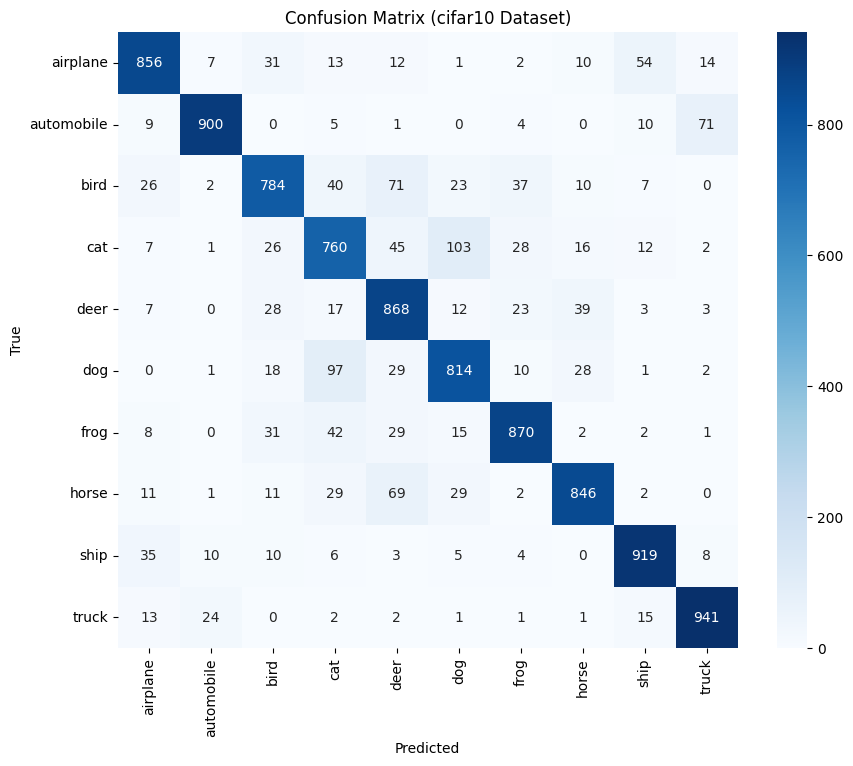

In [19]:
# Generate and display normalized confusion matrix heatmap
plot_confusion_matrix(model=model, dataset=test_ds, dataset_name=DATASET_NAME)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


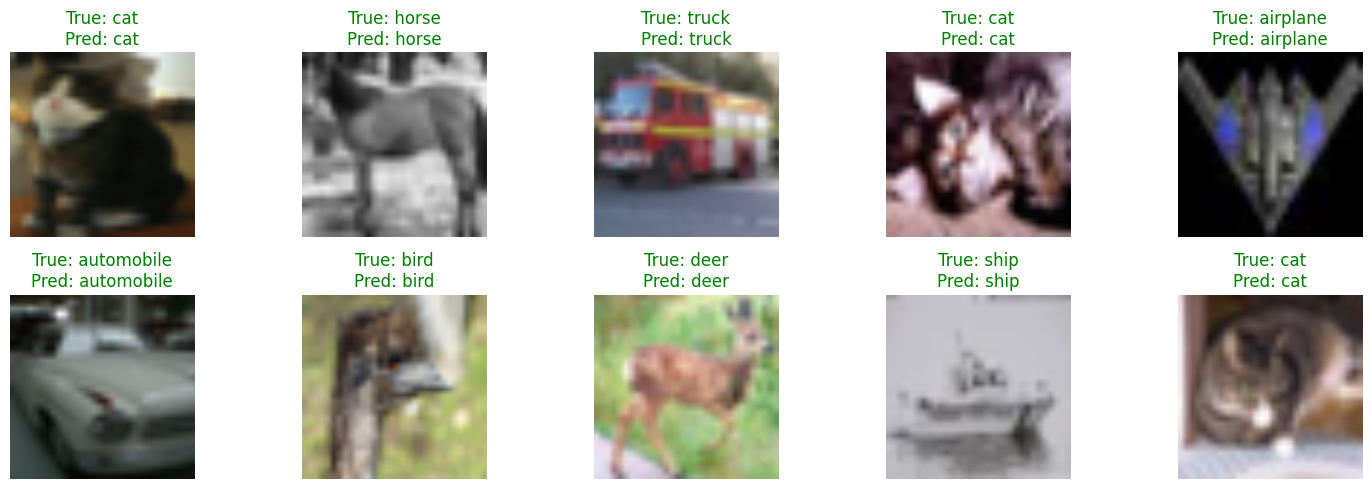

In [20]:
# Visualize random test set samples with green/red prediction status labels
plot_sample_predictions(
    model=model,
    dataset=test_ds,
    dataset_name=DATASET_NAME,
    num_samples=10
)

## Evaluation on Oxford-Pet dataset

In [6]:
DATASET_NAME = "oxford_pet"
BATCH_SIZE = 64

_, _, test_ds = prepare_oxford_pet_dataset(batch_size=BATCH_SIZE)

print(f"\nSuccessfully loaded {DATASET_NAME.upper()} data pipelines.")


Successfully loaded OXFORD_PET data pipelines.


In [7]:
# Path for best saved model
BEST_MODEL_PATH = f"../saved_models/mobilenet_{DATASET_NAME}_best_model.keras"

if os.path.exists(BEST_MODEL_PATH):
    model = tf.keras.models.load_model(BEST_MODEL_PATH)
    print("Best model loaded successfully.")
else:
    raise FileNotFoundError("No saved model or weights found. Please train the model first.")

Best model loaded successfully.


In [8]:
# Display network architecture summary
model.summary()

Model: "MobileNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_tensor_5CLONE             │ (None, 224, 224, 3)    │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 37)             │        47,397 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,400,177 (9.16 MB)

 Trainable params: 47,397 (185.14 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 94,796 (370.30 KB)

Training history loaded successfully.


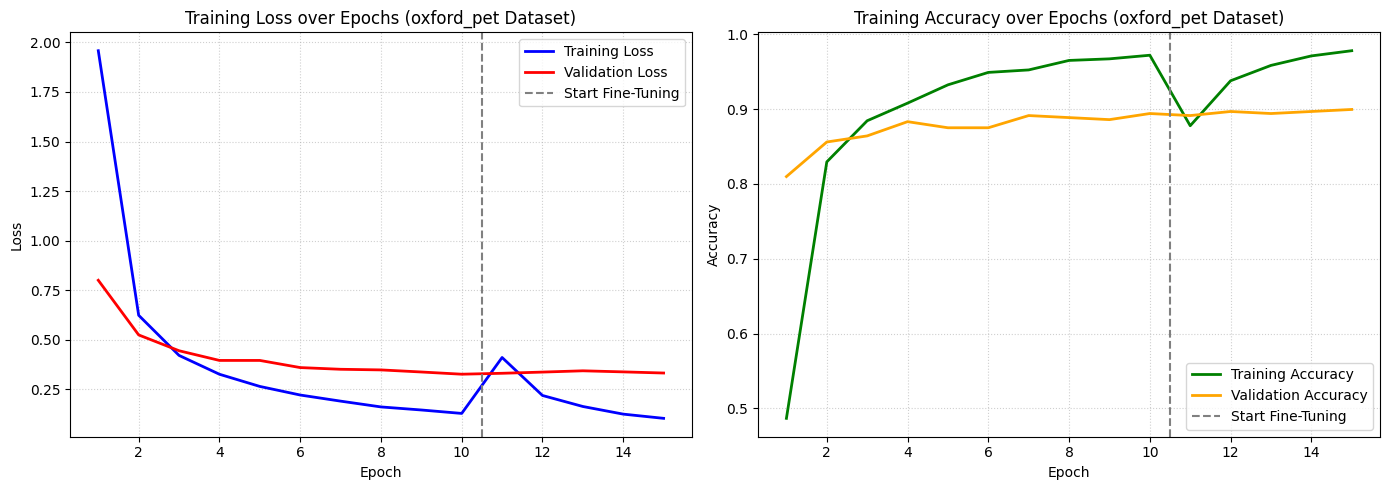

In [9]:
HISTORY_PATH = f"../saved_models/mobilenet_{DATASET_NAME}_history.csv"

if os.path.exists(HISTORY_PATH):
    # Load history from CSV file into a Pandas DataFrame
    history_dict = load_history_from_csv(HISTORY_PATH, warmup_epochs=10)
    print("Training history loaded successfully.")
else:
    raise FileNotFoundError(f"History file not found at: {HISTORY_PATH}")

# Plot training & validation loss and accuracy curves across epochs
plot_training_hist_dict(history_dict, dataset_name=DATASET_NAME)

In [10]:
trainer = MobileNetTransferTrainer(model=model)

# Evaluate model performance on unseen test data
results = trainer.evaluate(test_ds, dataset_name=DATASET_NAME)

print(f"Test Accuracy ({DATASET_NAME.upper()}): {results['accuracy'] * 100:.2f}%")
print(f"Test Loss ({DATASET_NAME.upper()}): {results['loss']:.4f}")

--- Evaluating MobileNet on (oxford_pet) Test Data ---
58/58 ━━━━━━━━━━━━━━━━━━━━ 18s 137ms/step - accuracy: 0.8746 - loss: 0.3806 - top_2_accuracy: 0.9542
Test Accuracy (OXFORD_PET): 87.46%
Test Loss (OXFORD_PET): 0.3806


58/58 ━━━━━━━━━━━━━━━━━━━━ 11s 117ms/step


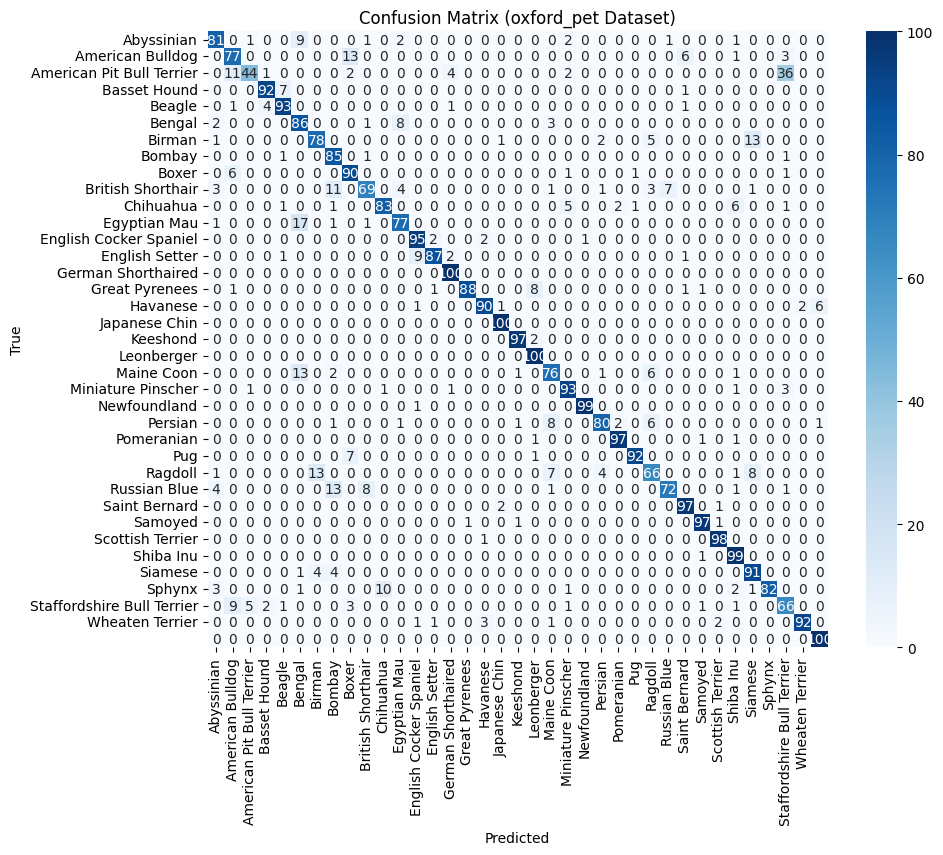

In [11]:
# Generate and display normalized confusion matrix heatmap
plot_confusion_matrix(model=model, dataset=test_ds, dataset_name=DATASET_NAME)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


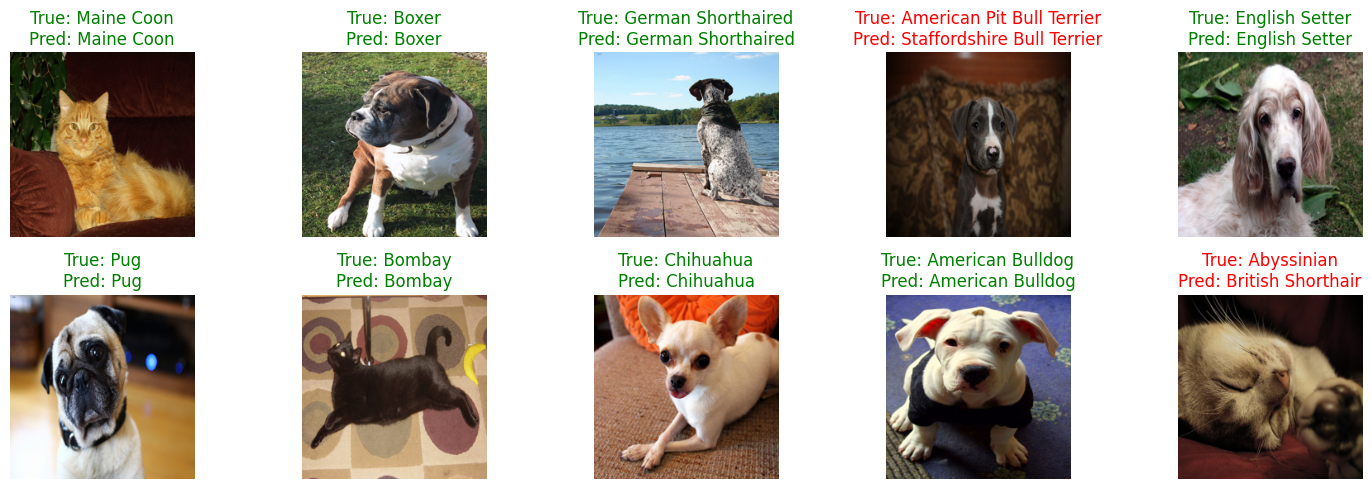

In [18]:
# Visualize random test set samples with green/red prediction status labels
plot_sample_predictions(
    model=model,
    dataset=test_ds,
    dataset_name=DATASET_NAME,
    num_samples=10
)